# Pontificia Universidad Javeriana
## Facultad de Ingeniería — Carrera de Bioingeniería
### Bioinformática (Periodo 2026-2)
### Segundo Parcial Práctico: Genómica Comparativa, Ensamblaje y Bioprospección en Biolixiviación

---

**Fecha de Asignación:** Jueves 22 de octubre de 2026  
**Tiempo de Desarrollo:** Una semana para su entrega   
**Profesor:** Juan Sebastián Malagón  
**Grupo de Trabajo:** Grupo 2 — *Acidithiobacillus ferrooxidans*  

| Integrante | Documento / ID | Correo Institucional |
| :--- | :--- | :--- |
| **Estudiante 1:** | | |
| **Estudiante 2:** | | |
| **Estudiante 3:** | | |

---

# Introducción y Contexto Biológico-Industrial

En el parcial anterior se confirmó, a partir de datos genómicos, la identidad del microorganismo acidófilo extremo y quimiolitótrofo de hierro y azufre aislado en **Drenajes Ácidos de Minas (DAM)**: ***Acidithiobacillus ferrooxidans***. 

La empresa minera y biotecnológica aliada tiene un alto interés en la explotación comercial y optimización de procesos de **biolixiviación** de minerales sulfurados (como calcopirita, $\text{CuFeS}_2$, y pirita, $\text{FeS}_2$, para la recuperación biohidrometalúrgica de cobre y oro), biominería y biorremediación de efluentes mineros ácidos altamente tóxicos.

No obstante, antes de realizar cuantiosas inversiones de capital a escala de pilas de lixiviación (*heap leaching*) o biorreactores industriales de tanque agitado continuo, la compañía requiere evaluar **alternativas industriales de microorganismos semejantes** pertenecientes al mismo gremio metabólico que coexistan en dicho ecosistema extremo o en nichos ecológicos afines. Para este análisis comparativo, el centro de secuenciación entregó las lecturas crudas de un nuevo aislado del ecosistema y una colección ambiental de secuencias homólogas.

<div align="center">
  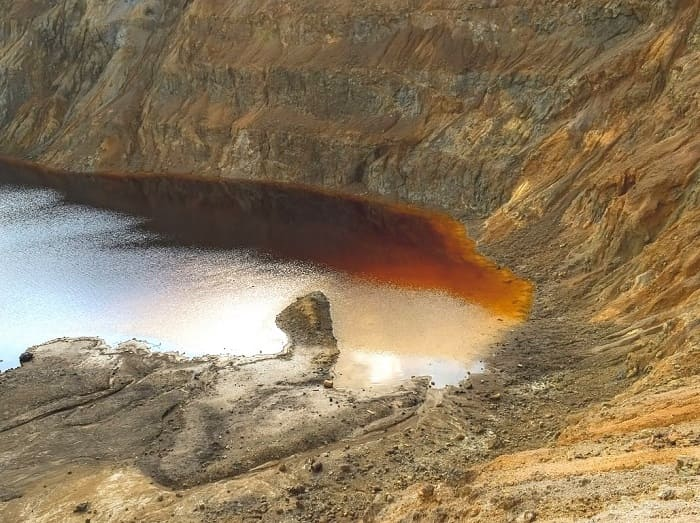
  <br>
  <em><strong>Figura 1:</strong> Ecosistema extremo de Drenaje Ácido de Minas (DAM / AMD), caracterizado por pH extremadamente ácido (&lt; 2.5) y altas concentraciones de metales pesados disueltos.</em>
</div>

### Fundamentación Técnica del Marcador Molecular *gyrB* (GO:0003918)
Como marcador molecular de alta resolución utilizaremos el gen ***gyrB***, que codifica para la subunidad B de la ADN girasa bacteriana (topoisomerasa tipo II, término ontológico **[GO:0003918](http://amigo.geneontology.org/amigo/term/GO:0003918)**). 

* **Función Biológica:** La ADN girasa es una enzima tetramérica esencial universal de copia única en bacterias (compuesta por dos subunidades A y dos B, $A_2B_2$) que cataliza la introducción de superenrollamiento negativo dependiente de ATP en la doble hélice de ADN, aliviando la tensión torsional generada durante los procesos de replicación y transcripción cromosomal.
* **Ventaja Filogenética frente al 16S ARNr:** Tradicionalmente se ha utilizado el gen ribosomal 16S ARNr para la taxonomía bacteriana. Sin embargo, en bacterias acidófilas lixiviantes como las del género *Acidithiobacillus*, el 16S ARNr posee una tasa de evolución y divergencia excesivamente lenta, lo que ocasiona que múltiples especies crípticas o linajes evolutivamente divergentes presenten una identidad de secuencia superior al 99%, impidiendo resolver su filogenia fina. Por el contrario, el gen ***gyrB*** presenta una tasa de sustitución nucleotídica (especialmente en terceras posiciones de codón) significativamente mayor que el 16S ARNr, conservando a la vez sus dominios catalíticos y estructurales esenciales sin transferencia horizontal detectable. Esto le confiere un **poder de resolución taxonómica superior** para discriminar especies crípticas y delinear linajes filogenéticos estrechamente emparentados dentro de la misma familia y género.

> ⚠️ **RESTRICCIÓN CRÍTICA DE INFRAESTRUCTURA (MÁXIMO 2 HILOS DE CÓMPUTO):**
> Dado el entorno compartido del servidor institucional y la alta concurrencia de procesamiento, es de **carácter obligatorio** configurar todas las herramientas de cómputo (`FastQC`, `Trimmomatic`, `SPAdes`, `QUAST`, `BUSCO`, `Prokka`, `eggNOG-mapper`, scripts de Python) a un **máximo estricto de 2 hilos de procesamiento** (`-t 2`, `--cpus 2`, `-threads 2` o `n_jobs=2`).
> 
> *El desacato a esta norma sobrecargará los nodos compartidos del servidor y conllevará penalización directa sobre la calificación del parcial.*

---

### Material Proporcionado en la Carpeta `./data/`

| Archivo | Formato | Descripción |
| :--- | :--- | :--- |
| `reads_R1.fastq` | FASTQ (Illumina) | Lecturas de secuenciación directa (*Forward*, R1) crudas del nuevo aislado de DAM. |
| `reads_R2.fastq` | FASTQ (Illumina) | Lecturas de secuenciación reversa (*Reverse*, R2) crudas del nuevo aislado de DAM. |
| `coleccion_gyrB.fasta` | FASTA (Nucleótidos) | Colección ambiental de 20 secuencias homólogas del gen *gyrB* de taxones relacionados y linajes externos. |

---

## Punto 0: Preparación del Entorno de Trabajo

Antes de iniciar la ejecución de los análisis bioinformáticos, prepare su espacio de trabajo:
1. Cree una estructura organizada de carpetas dentro del directorio de trabajo para almacenar de manera modular los resultados intermedios y finales:
   * `./resultados/01_control_calidad/`
   * `./resultados/02_ensamblaje/`
   * `./resultados/03_anotacion/`
   * `./resultados/04_comparativa_pcoa/`
   * `./resultados/05_filogenia/`
2. Verifique la disponibilidad de las herramientas bioinformáticas en el entorno de conda (`bioinformatics`) y la existencia de los archivos de entrada en `./data/`.
3. Importe las librerías de Python requeridas (`os`, `sys`, `subprocess`, `numpy`, `pandas`, `matplotlib.pyplot`, `Bio.SeqIO`, `Bio.Phylo`, `sklearn.manifold`, `scipy.spatial.distance`).

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 1: Preprocesamiento y Control de Calidad de Lecturas

### Fundamentación Bioinformática
La secuenciación masiva por síntesis (Illumina) genera millones de lecturas cortas pareadas (*paired-end*). No obstante, factores experimentales como el decaimiento de la señal de fluorescencia hacia los extremos 3' de las lecturas, la formación de dímeros de adaptadores de ligación o errores en la incorporación enzimática reducen progresivamente la calidad Phred ($Q = -10 \log_{10} P_{\text{error}}$). 

Es imprescindible evaluar la calidad inicial de las lecturas crudas y aplicar un proceso riguroso de recorte y filtrado (*trimming*) antes de intentar el ensamblaje *de novo*, ya que los errores de secuenciación introducen *k-mers* espurios que complejizan exponencialmente el grafo de de Bruijn.

### Documentación Oficial de las Herramientas:
* **FastQC:** [Manual y Guía Oficial de FastQC (Babraham Bioinformatics)](https://www.bioinformatics.babraham.ac.uk/projects/fastqc/Help/)
* **MultiQC:** [Documentación Oficial de MultiQC](https://multiqc.info/docs/)
* **Trimmomatic:** [Manual de Usuario Oficial de Trimmomatic (Usadel Lab)](http://www.usadellab.org/cms/?page=trimmomatic)

---

### 1.1 Control de Calidad Inicial (FastQC y MultiQC)
* Ejecute `fastqc` sobre las lecturas crudas `reads_R1.fastq` y `reads_R2.fastq` empleando estrictamente **2 hilos** (`-t 2`) y dirigiendo la salida a la carpeta de calidad.
* Consolide los reportes generados en un único informe interactivo empleando `multiqc`.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.2 Depuración y Filtrado de Calidad con Trimmomatic
* Ejecute `trimmomatic` en modo pareado (**PE**) empleando estrictamente **2 hilos** (`-threads 2`).
* Configure y justifique los parámetros de limpieza:
  * Eliminación de secuencias de adaptadores (`ILLUMINACLIP`).
  * Filtrado por ventana deslizante para cortar regiones con calidad media deficiente (`SLIDINGWINDOW:4:20`).
  * Descarte de lecturas que queden por debajo de una longitud mínima viable (`MINLEN:50`).
* Genere los archivos de lecturas depuradas pareadas (`R1_paired.fastq.gz`, `R2_paired.fastq.gz`) y no pareadas (*unpaired*).

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 1.3 Control de Calidad Post-Trimming
* Ejecute nuevamente `fastqc` (`-t 2`) sobre los archivos pareados depurados (`R1_paired` y `R2_paired`).
* Genere el reporte consolidado final con `multiqc` para certificar la eliminación de adaptadores y el incremento en la calidad Phred media.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 2: Ensamblaje *De Novo* y Evaluación Genómica

### Fundamentación Bioinformática
El ensamblaje *de novo* consiste en reconstruir la secuencia completa del cromosoma bacteriano a partir del conjunto de lecturas pareadas limpias sin utilizar una secuencia de referencia previa. **SPAdes** (*St. Petersburg Genome Assembler*) utiliza grafos de de Bruijn multiescala combinando múltiples tamaños de *k-mer* para resolver simultáneamente regiones de alta cobertura y secuencias repetitivas.

Una vez ensamblados los **contigs**, la calidad debe validarse bajo dos dimensiones complementarias:
1. **Contigüidad estructural:** Evaluada con **QUAST**, midiendo estadísticas como el número total de contigs, la longitud acumulada del genoma ensamblado, el porcentaje de GC (%GC) y el estadístico **$N_{50}$** (la longitud del contig más corto tal que la suma de todos los contigs de igual o mayor tamaño abarca al menos el 50% de la longitud total del ensamblaje).
2. **Completitud y redundancia biológica:** Evaluada con **BUSCO** (*Benchmarking Universal Single-Copy Orthologs*), que cuantifica la presencia y estado (completo, duplicado, fragmentado, ausente) de un catálogo de genes esenciales conservados en copia única para el linaje bacteriano.

### Documentación Oficial de las Herramientas:
* **SPAdes:** [Manual de Usuario Oficial de SPAdes (Algorithmic Biology Lab)](https://cab.spbu.ru/software/spades/)
* **QUAST:** [Manual Oficial de QUAST (SourceForge)](https://quast.sourceforge.net/docs/manual.html)
* **BUSCO:** [Guía Oficial de Usuario de BUSCO (Ezlab)](https://busco.ezlab.org/busco_userguide.html)

---

### 2.1 Ensamblaje *De Novo* con SPAdes
* Ejecute `spades.py` utilizando como entrada las lecturas pareadas limpias obtenidas en el Punto 1 (`R1_paired` y `R2_paired`).
* Utilice el modo para aislamientos bacterianos (`--isolate`), un límite de memoria prudente (ej. `-m 3` o `-m 4`) y estrictamente **2 hilos** (`-t 2`).
* Identifique la ubicación de los archivos resultantes `contigs.fasta` y `scaffolds.fasta`.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.2 Evaluación de la Contigüidad con QUAST
* Ejecute `quast.py` sobre el archivo `contigs.fasta` generado por SPAdes empleando estrictamente **2 hilos** (`-t 2`).
* Despliegue e inspeccione el archivo de reporte tabular `report.txt`.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 2.3 Evaluación de la Completitud Biológica con BUSCO
* Ejecute `busco` sobre el archivo `contigs.fasta` utilizando el modo genoma (`-m genome`), el catálogo taxonómico bacteriano (`-l bacteria_odb10`) y estrictamente **2 hilos** (`--cpu 2`).
* Despliegue el resumen de resultados (`short_summary.*.txt`).

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 3: Anotación Estructural, Funcional y Extracción del Marcador *gyrB*

### Fundamentación Bioinformática
Una vez reconstruidos los contigs genómicos, el siguiente paso consiste en caracterizar el contenido biológico del genoma mediante dos fases metodológicas:
1. **Anotación Estructural:** Identificación y delimitación de los elementos génicos (coordenadas de inicio y parada de marcos abiertos de lectura - ORFs, ARNt, ARNr) empleando **Prokka**, que integra internamente herramientas como Prodigal y Aragorn para generar secuencias traducidas de proteínas (`.faa`) y secuencias codificantes de nucleótidos (`.ffn`).
2. **Anotación Funcional:** Asignación de significancia biológica a las secuencias polipeptídicas predichas mediante ortología con **eggNOG-mapper** (basado en la base de datos de Grupos de Ortología No Supervisados eggNOG). Esto asigna términos estandarizados de la Ontología Génica (**GO terms**), identificadores COG y rutas metabólicas KEGG.

En este punto localizaremos con precisión la secuencia del gen ***gyrB*** asignada al término ontológico **GO:0003918** (*DNA topoisomerase type II (ATP-hydrolyzing) activity*) y recuperaremos su identificador de *locus tag* para extraer su secuencia nucleotídica completa mediante **SeqKit** o BioPython.

### Documentación Oficial de las Herramientas:
* **Prokka:** [Manual Oficial de Prokka (Debian Packages & Manual)](https://manpages.debian.org/testing/prokka/prokka.1.en.html)
* **eggNOG-mapper:** [Documentación Oficial de eggNOG-mapper (EMBL)](http://eggnog-mapper.embl.de/documentation.html)
* **SeqKit:** [Manual de Usuario Oficial de SeqKit](https://bioinf.shenwei.me/seqkit/)

---

### 3.1 Anotación Estructural con Prokka
* Ejecute `prokka` sobre el archivo de contigs (`contigs.fasta`) estableciendo un prefijo identificativo (ej. `--prefix A_ferrooxidans_query`) y limitando el procesamiento estrictamente a **2 hilos** (`--cpus 2`).
* Verifique la generación de los archivos clave:
  * `*.faa`: Secuencias de aminoácidos de las proteínas predichas.
  * `*.ffn`: Secuencias de nucleótidos de las regiones codificantes de genes (CDS).
  * `*.gff` y `*.tsv`: Tablas de coordenadas genómicas y resumen de anotación.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.2 Anotación Funcional con eggNOG-mapper
* Ejecute `emapper.py` utilizando como archivo de entrada las proteínas predichas por Prokka (`*.faa`).
* Configure el método de alineamiento con Diamond (`-m diamond`) y limite el cómputo estrictamente a **2 hilos** (`--cpu 2`).
* **Parámetros de aceleración:** Añada los argumentos `--dmnd_algo ctg --sensmode default --dmnd_iterate no` para acelerar sustancialmente la ejecución de DIAMOND.
* Identifique el archivo de anotaciones de salida (`*.emapper.annotations`).

In [ ]:
# 3.2 Anotación funcional con eggNOG-mapper (--cpu 2 --dmnd_algo ctg --sensmode default --dmnd_iterate no)
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.3 Búsqueda, Localización e Identificación del Gen *gyrB* (GO:0003918)
* Filtre el archivo de anotaciones funcionales (`*.emapper.annotations`) o la tabla de Prokka (`*.tsv`) buscando la asociación con el término ontológico de la subunidad B de la ADN girasa: **`GO:0003918`** o la descripción funcional (*DNA gyrase subunit B* / *topoisomerase type II*).
* Recupere y registre el identificador exacto de **Locus Tag** (ej. `PROKKA_xxxxx`) asignado a esta secuencia.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 3.4 Extracción de la Secuencia Nucleotídica de *gyrB*
* Utilice `seqkit grep` (o un script con `Bio.SeqIO` de BioPython) para buscar el *locus tag* identificado dentro del archivo de nucleótidos de Prokka (`*.ffn`).
* Extraiga la secuencia completa en formato FASTA y guárdela con un identificador claro (ej. `A_ferrooxidans_query` o `af_gyrB.fasta`).
* Imprima la cabecera, verifique que la longitud sea coherente (~2000 - 2400 bp) y valide que el marco de lectura inicie con codón de inicio (ATG/GTG) y termine en codón de parada.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 4: Genómica Comparativa y Detección de Organismos Fuera de Distribución (OFDs) con PCoA

### Fundamentación Bioinformática
El archivo `./data/coleccion_gyrB.fasta` contiene secuencias homólogas del gen *gyrB* provenientes de diversos aislados ambientales y cepas de referencia. Antes de reconstruir relaciones evolutivas de grano fino, es fundamental realizar un análisis exploratorio multivariado para certificar la homogeneidad de la colección y detectar posibles **OFDs** (*Organismos Fuera de la Distribución*, o taxones atípicos/contaminantes que no pertenecen al clado de interés).

El flujo analítico contempla:
1. **Alineamiento Múltiple de Secuencias (MSA):** Con **MUSCLE**, para establecer correspondencia posicional homóloga entre las bases nucleotídicas de todas las secuencias.
2. **Matriz de Distancias de Hamming Normalizada:** Cálculo de la distancia genética de pares de secuencias alineadas:
   $$D_{ij} = \frac{1}{L} \sum_{k=1}^L \mathbb{I}(s_{ik} \neq s_{jk})$$
   donde $L$ es la longitud total del alineamiento y $\mathbb{I}$ es la función indicadora que contabiliza los sitios con desajuste (*mismatch*).
3. **Análisis de Coordenadas Principales (PCoA / MDS clásico):** A partir de la matriz de distancias $D$, se calcula la matriz de producto interno centrada de Gower:
   $$B = -\frac{1}{2} H D^2 H, \quad \text{donde } H = I - \frac{1}{n} \mathbf{1}\mathbf{1}^T$$
   La descomposición espectral de $B$ permite proyectar los taxones en un espacio ortogonal de baja dimensionalidad que maximiza la preservación de distancias genéticas.
4. **Detección y Exclusión de OFDs:** Los taxones que se ubiquen a distancias extremas en los componentes principales (especialmente a lo largo de PC1) representan linajes filogenéticamente distantes (ej. bacterias de otros filos como Firmicutes, Actinobacteria o Bacteroidetes) cuya inclusión en análisis filogenéticos intragénero introduce distorsiones por atracción de ramas largas (*long-branch attraction*).

### Documentación Oficial de las Herramientas:
* **MUSCLE:** [Manual Oficial de MUSCLE (Drive5 Robert Edgar)](https://drive5.com/muscle/manual/)
* **SciPy Spatial Distance:** [Documentación Oficial de SciPy Distance Functions](https://docs.scipy.org/doc/scipy/reference/spatial.distance.html)
* **scikit-learn MDS / PCoA:** [Documentación de scikit-learn MDS](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.MDS.html)
* **Matplotlib Pyplot Scatter:** [Documentación de la función scatter en Matplotlib](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html)

---

### 4.1 Fusión de Secuencias en un Multifasta Combinado
* Combine la secuencia de *gyrB* extraída de su aislado en el Punto 3 con las 20 secuencias presentes en `./data/coleccion_gyrB.fasta`.
* Asegúrese de que el encabezado del aislado problema sea claro e inequívoco (ej. `>A_ferrooxidans_query`) y verifique que el archivo resultante contenga exactamente 21 secuencias FASTA.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.2 Alineamiento Múltiple de Secuencias con MUSCLE
* Ejecute `muscle` para realizar el alineamiento múltiple de secuencias (MSA) sobre el archivo multifasta combinado.
* Compruebe que todas las secuencias en el alineamiento resultante tengan la misma longitud en pares de bases (incluyendo *gaps* `-`).

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.3 Cálculo de la Matriz de Distancias de Hamming
* Cargue el alineamiento generado empleando `Bio.SeqIO` o `Bio.AlignIO`.
* Programe el cálculo de la matriz de distancias simétrica de Hamming normalizada entre todos los pares de secuencias utilizando NumPy / SciPy.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.4 Análisis de Coordenadas Principales (PCoA / MDS Clásico)
* Aplique PCoA (centrado de Gower y descomposición en valores y vectores propios con NumPy, o mediante `sklearn.manifold.MDS` con disimilitud precomputada).
* Calcule el porcentaje de varianza explicada por cada una de las coordenadas principales (PC1, PC2 y PC3):
  $$\%\text{ Varianza } PC_k = \frac{\lambda_k}{\sum_{i} \lambda_i} \times 100$$

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.5 Gráfico de Dispersión Bidimensional (PC1 vs PC2) e Identificación de OFDs
* Construya un gráfico de dispersión bidimensional (PC1 vs PC2) con `matplotlib.pyplot.scatter`.
* Incorpore:
  * Etiquetas claras en los ejes indicando el porcentaje de varianza explicada por cada componente.
  * Etiquetas de texto con el nombre de cada taxón junto a su coordenada.
  * Esquema de colores contrastante: un color para su aislado (`A_ferrooxidans_query`), otro para las bacterias del grupo de interés (*Acidithiobacillus* y afines), y un color de alerta para los **OFDs** detectados.
  * Leyenda, rejilla sutil y título profesional.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 4.6 Depuración y Eliminación de los OFDs
* Identifique la lista de taxones que constituyen los OFDs (aquellos aislados en el extremo opuesto de PC1).
* Genere un nuevo archivo FASTA depurado que contenga exclusivamente las secuencias del grupo de interés y su aislado problema, excluyendo los OFDs identificados.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


---
## Punto 5: Señales Evolutivas y Reconstrucción Filogenética

### Fundamentación Bioinformática
Con la colección depurada libre de secuencias atípicas (OFDs), procedemos a la reconstrucción del árbol filogenético para ubicar con precisión la posición evolutiva del nuevo aislado de DAM e identificar sus especies hermanas (*sister taxa*).

1. **Modelo de Distancia de Jukes-Cantor (JC69):** La simple distancia de Hamming subestima la verdadera distancia evolutiva debido a sustituciones múltiples en un mismo sitio durante el tiempo geológico (*homoplasias* o sustituciones invisibles). El modelo de Jukes-Cantor corrige esta subestimación asumiendo tasas de mutación idénticas y frecuencias de bases equiprobables ($1/4$):
   $$d = -\frac{3}{4} \ln\left(1 - \frac{4}{3} p\right)$$
   donde $p$ es la proporción de nucleótidos divergentes observados.

### Documentación Oficial de las Herramientas:
* **BioPython Phylo:** [Wiki Oficial de BioPython Phylo](https://biopython.org/wiki/Phylo)
* **Bio.Phylo.TreeConstruction:** [Documentación del Módulo TreeConstruction (BioPython API)](https://biopython.org/docs/latest/api/Bio.Phylo.TreeConstruction.html)
* **Tutorial Oficial de BioPython (Capítulo 13: Filogenética):** [BioPython Official Tutorial - Chapter 13](https://biopython.org/DIST/docs/tutorial/Tutorial.html#sec379)

---

### 5.1 Realineamiento y Estimación de Distancias Genéticas con Jukes-Cantor
* Ejecute el realineamiento de las secuencias depuradas (o recorte el alineamiento previo para conservar solo las secuencias del grupo sin OFDs).
* Emplee el módulo `Bio.Phylo.TreeConstruction.DistanceCalculator(model='jukes-cantor')` para computar la matriz de distancias filogenéticas corregidas.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.2 Reconstrucción del Árbol Filogenético
* Emplee `DistanceTreeConstructor` con el algoritmo Neighbor-Joining (`nj()`)  sobre la matriz calculada para reconstruir la topología del árbol filogenético .
* Guarde el árbol resultante en formato Newick (`.nwk`).

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)


### 5.3 Visualización e Interpretación del Árbol Filogenético
* Visualice el árbol filogenético con `Bio.Phylo.draw` (usando Matplotlib para personalización gráfica) o imprima la estructura con `Bio.Phylo.draw_ascii`.
* Destaque explícitamente:
  * El clado donde se sitúa su aislado problema (`A_ferrooxidans_query`).
  * Las especies hermanas (*sister taxa*) inmediatas.
  * La longitud de las ramas evolutivas.

In [ ]:
# >>> TU CÓDIGO AQUÍ (Recuerda utilizar máximo 2 hilos)
